# Experiment 03.🥾➿ Bootstrap Distribution 🥾➿

This experiment examines what distribution of estimates produces a bootstrap confidence interval.

Using 10,000 paired bootstrap replicates based on the original sample (n = 300), I explore the distributions of Cohen's κ and Δκ and examine how their percentiles are used to construct 95% confidence intervals.

## Contents

1. **Question**
2. **Data and Procedure**
3. **What I Will Examine**
4. **Reproduction Check**
5. **Bootstrap Distribution**
   - 5.1. Baseline κ
   - 5.2. Δκ by Condition
   - 5.3. Percentile Intervals
6. **Observations**

This notebook reads a local file (the human labels) from the original study's repository, so it runs only on the local machine.


## 1. Question 🤔

What distribution of estimates produces a bootstrap confidence interval?

In the original study, exclusion-rule replacement produced the following result.

| Measure | Value |
|---|---:|
| Estimated Δκ | −0.1062 |
| 95% Bootstrap CI | [−0.1576, −0.0556] |

The confidence interval provides two endpoints, but these values alone do not reveal the center or shape of the bootstrap distribution.

This experiment examines the distribution of bootstrap estimates and how its 2.5th and 97.5th percentiles produce the reported confidence interval.

## 2. Data and Procedure

The bootstrap replicates were regenerated in `preview/make_replicates.py` by calling the original study's functions (`scripts/scorer.py`: `draw_indices`, `bootstrap_replicates`, `summarize_replicates`) unchanged, with the original seed. This notebook reads the saved replicates and does not resample again.

The original procedure, with its source text:

| Item | Rule | Source text |
|---|---|---|
| Resampling unit | One utterance is drawn, and its human label and all six condition labels travel together. | 06-analysis §6.2.1: "Carry the human label, all condition final labels, and all missingness states together, including repeated occurrences of a sampled index." |
| Same draw for every condition | Conditions are not resampled independently. | 06-analysis §6.2.1: "Use the same draw for every condition." scorer.py `bootstrap_replicates`: "Resampling the same utterances together in every condition preserves the within-item pairing and the item-level covariance between conditions". |
| Random number generator and seed | PCG64 with seed 20260919, the whole index array in one call. | scorer.py `draw_indices`: "`numpy.random.Generator(numpy.random.PCG64(seed)).integers(0, n, size=(n_replicates, n))`: the bit generator is named explicitly, not taken from default_rng, and the whole array is produced in one call so that the order of the draws is fixed." `BOOTSTRAP_SEED = 20260919`. |
| Number of replicates | B = 10,000. | scorer.py: `N_REPLICATES = 10_000`. 06-analysis §6.2.1: "10,000 replicates, and bootstrap seed 20260919". |
| Row order | Drawn index i refers to the i-th row of the table ordered by utterance ID. | 06-analysis §6.2.1: "The table rows are ordered by `utterance_id` ascending, and a drawn index i (0-based) refers to the i-th row of that table". |
| Interval | 2.5th and 97.5th percentiles, linear interpolation. | scorer.py `summarize_replicates`: "the two-sided 95% interval is `numpy.percentile(values, [2.5, 97.5], method="linear")`". |
| NumPy version | The seed reproduces the draws only under the same NumPy version. | 06-analysis §6.2.1: "the seed reproduces the intervals only together with the NumPy version". Scoring record §3: NumPy 2.3.5. |

The code below reads `preview/replicates.csv` and builds the 300-row label table with the same join as Experiment 02, Section 2.1, to compute the point estimates with the original `kappa` function.

**Sources:** [decisions/06-analysis.md §6.2.1](https://github.com/geekinthegit/coding-manual-ablation/blob/main/decisions/06-analysis.md), [scripts/scorer.py](https://github.com/geekinthegit/coding-manual-ablation/blob/main/scripts/scorer.py), [Main Scoring Record, Section 3](https://github.com/geekinthegit/coding-manual-ablation/blob/main/reports/main-scoring-record-2026-09-24.md)

In [1]:
# 2. Data and Procedure — replicates and point estimates

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert np.__version__ == "2.3.5", np.__version__   # the NumPy version under which the draws were generated

# Input paths (all read-only)
REPLICATES = Path("preview") / "replicates.csv"
ABLATION_ROOT = Path.home() / "coding-manual-ablation"
SCORING_LABELS = ABLATION_ROOT / "data" / "scoring_labels.csv"              # git-ignored: read in place, not copied
FINAL_LABELS = ABLATION_ROOT / "runs" / "main-2026-09-24" / "final_labels.csv"
SCRIPTS_DIR = ABLATION_ROOT / "scripts"

for path in (REPLICATES, SCORING_LABELS, FINAL_LABELS, SCRIPTS_DIR):
    if not path.exists():
        raise FileNotFoundError(f"Required input not found: {path}")

# Importing scorer also imports openai through its dependencies; no API key is read and no call is made.
sys.dont_write_bytecode = True        # do not write __pycache__ into the original repository
sys.path.insert(0, str(SCRIPTS_DIR))
from tags import TAG_TO_CATEGORY
from scorer import kappa

CONDITIONS = [
    "baseline",
    "definition_replacement",
    "example_replacement",
    "exclusion_rule_replacement",
    "negative_control",
    "names_only",
]
REPLACEMENTS = CONDITIONS[1:5]
N, B = 300, 10_000

# Bootstrap replicates (preview/make_replicates.py)
replicates = pd.read_csv(REPLICATES)
EXPECTED_COLUMNS = ["replicate", "kappa_baseline", *[f"delta_kappa_{c}" for c in REPLACEMENTS]]
assert len(replicates) == B
assert list(replicates.columns) == EXPECTED_COLUMNS
assert replicates["replicate"].tolist() == list(range(1, B + 1))
assert replicates.notna().all().all()

# 300-row label table: the same join as Experiment 02, Section 2.1 (full category names kept for kappa)
final_long = pd.read_csv(FINAL_LABELS)
assert set(final_long["status"]) == {"resolved"}
model = final_long.pivot(index="utterance_id", columns="condition", values="final_label")[CONDITIONS]
model.columns.name = None

human_raw = pd.read_csv(SCORING_LABELS, keep_default_na=False, na_values=[""], usecols=["source_id", "Tag"])
assert human_raw["source_id"].is_unique
human = human_raw.set_index("source_id")["Tag"].astype(int).map(TAG_TO_CATEGORY).rename("human")

labels = model.join(human, how="left").reset_index()[["utterance_id", "human", *CONDITIONS]]
assert len(labels) == N
assert labels.notna().all().all()
assert labels["utterance_id"].is_unique

# Point estimates from the original 300 rows
human_names = labels["human"].tolist()
kappa_point = {c: kappa(human_names, labels[c].tolist()).kappa for c in CONDITIONS}
delta_point = {c: kappa_point[c] - kappa_point["baseline"] for c in REPLACEMENTS}

print(f"Replicates: {len(replicates)} rows, columns {list(replicates.columns)}")
print(f"Label table: {len(labels)} rows")
print()
print(f"{'Condition':<28} {'kappa':>8} {'delta':>8}")
print(f"{'baseline':<28} {kappa_point['baseline']:>8.4f} {'':>8}")
for c in REPLACEMENTS:
    print(f"{c:<28} {kappa_point[c]:>8.4f} {delta_point[c]:>+8.4f}")

Replicates: 10000 rows, columns ['replicate', 'kappa_baseline', 'delta_kappa_definition_replacement', 'delta_kappa_example_replacement', 'delta_kappa_exclusion_rule_replacement', 'delta_kappa_negative_control']
Label table: 300 rows

Condition                       kappa    delta
baseline                       0.6085         
definition_replacement         0.6067  -0.0018
example_replacement            0.5473  -0.0611
exclusion_rule_replacement     0.5023  -0.1062
negative_control               0.5852  -0.0232


## 3. What I Will Examine

This section was written after the figures were seen, so it is a checklist of questions, not a prediction.

- **Center.** How close is the median of the replicates to the point estimate, for baseline κ and for each Δκ?
- **Spread.** How wide is each 95% interval, and what is the standard deviation of the replicates?
- **Shape.** Is each distribution symmetric around its center, and does it have a longer tail on one side?
- **Interval position.** Which Δκ intervals include 0, and which lie entirely on one side of it?
- **Δκ versus baseline κ.** Is the Δκ interval narrower than the baseline κ interval, and what in the resampling procedure would make it so? The correlation between baseline κ and condition κ across replicates is computed in Section 5.2 for this question.

## 4. Reproduction Check

Two different kinds of values are checked against the scoring record.

- **(a) Point estimates.** Baseline κ and the four Δκ are computed directly from the original 300 rows. They use no random numbers and are compared with the estimates in Sections 8 and 9 of the record.
- **(b) Percentile bounds.** The 2.5th and 97.5th percentiles are computed from the 10,000 replicates of each column and compared with the 95% intervals in the record.

A point estimate is a statistic of the original sample. A percentile is a statistic of 10,000 resampled estimates. The mean or median of the replicates is not required to equal the point estimate.

The comparison table also reports the median, mean, and standard deviation of the replicates, which are not in the record.

**Source:** [Main Scoring Record, Sections 8 and 9](https://github.com/geekinthegit/coding-manual-ablation/blob/main/reports/main-scoring-record-2026-09-24.md)

In [2]:
# 4. Reproduction Check

# Scoring record values (Section 8: standalone kappa; Section 9: delta kappa)
RECORD_KAPPA = {
    "baseline":                   (0.6085, 0.5266, 0.6846),
    "definition_replacement":     (0.6067, 0.5252, 0.6824),
    "example_replacement":        (0.5473, 0.4658, 0.6239),
    "exclusion_rule_replacement": (0.5023, 0.4244, 0.5767),
    "negative_control":           (0.5852, 0.5060, 0.6605),
}
RECORD_DELTA = {
    "definition_replacement":     (-0.0018, -0.0384,  0.0360),
    "example_replacement":        (-0.0611, -0.1047, -0.0191),
    "exclusion_rule_replacement": (-0.1062, -0.1576, -0.0556),
    "negative_control":           (-0.0232, -0.0581,  0.0118),
}

# Statistics examined: column name, point estimate, record (estimate, lower, upper)
STATS = [("kappa_baseline", kappa_point["baseline"], RECORD_KAPPA["baseline"])]
STATS += [(f"delta_kappa_{c}", delta_point[c], RECORD_DELTA[c]) for c in REPLACEMENTS]

# (a) Point estimates from the original 300 rows
for col, point, (rec_est, _, _) in STATS:
    assert round(point, 4) == rec_est, (col, point)
for c in REPLACEMENTS:
    assert round(kappa_point[c], 4) == RECORD_KAPPA[c][0], c

# (b) Percentile bounds from the 10,000 replicates
percentiles = {}
for col, point, (_, rec_lo, rec_hi) in STATS:
    values = replicates[col].to_numpy()
    lo, mid, hi = np.percentile(values, [2.5, 50, 97.5], method="linear")
    assert round(lo, 4) == rec_lo, (col, lo)
    assert round(hi, 4) == rec_hi, (col, hi)
    percentiles[col] = (lo, mid, hi)

print("(a) point estimates match the scoring record to four decimal places")
print("(b) 2.5th and 97.5th percentiles match the scoring record to four decimal places")
print()
print(f"{'Statistic':<40} {'Point':>8} {'p2.5':>8} {'p50':>8} {'p97.5':>8} {'Mean':>8} {'SD':>8}  Record 95% CI")
for col, point, (rec_est, rec_lo, rec_hi) in STATS:
    values = replicates[col].to_numpy()
    lo, mid, hi = percentiles[col]
    print(f"{col:<40} {point:>8.4f} {lo:>8.4f} {mid:>8.4f} {hi:>8.4f} "
          f"{values.mean():>8.4f} {values.std(ddof=1):>8.4f}  [{rec_lo:.4f}, {rec_hi:.4f}]")

(a) point estimates match the scoring record to four decimal places
(b) 2.5th and 97.5th percentiles match the scoring record to four decimal places

Statistic                                   Point     p2.5      p50    p97.5     Mean       SD  Record 95% CI
kappa_baseline                             0.6085   0.5266   0.6083   0.6846   0.6075   0.0401  [0.5266, 0.6846]
delta_kappa_definition_replacement        -0.0018  -0.0384  -0.0019   0.0360  -0.0017   0.0190  [-0.0384, 0.0360]
delta_kappa_example_replacement           -0.0611  -0.1047  -0.0608  -0.0191  -0.0610   0.0217  [-0.1047, -0.0191]
delta_kappa_exclusion_rule_replacement    -0.1062  -0.1576  -0.1062  -0.0556  -0.1063   0.0260  [-0.1576, -0.0556]
delta_kappa_negative_control              -0.0232  -0.0581  -0.0233   0.0118  -0.0234   0.0178  [-0.0581, 0.0118]


## 5. Bootstrap Distribution

Each histogram shows the 10,000 replicate values of one statistic. The vertical lines mark the point estimate from the original 300 rows and the 2.5th and 97.5th percentiles that form the reported interval. The Δκ figures also mark 0.

### 5.1. Baseline κ

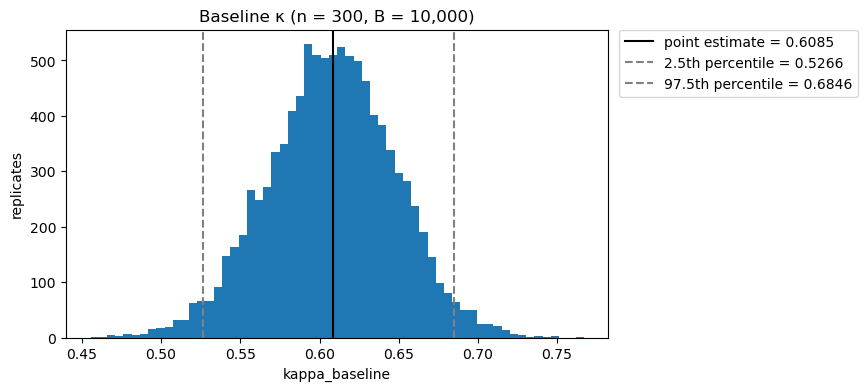

In [3]:
# 5.1. Baseline kappa

BINS = 60

def histogram(ax, values, point, title, xlabel, zero_line):
    lo, hi = np.percentile(values, [2.5, 97.5], method="linear")
    ax.hist(values, bins=BINS)
    ax.axvline(point, color="black", label=f"point estimate = {point:.4f}")
    ax.axvline(lo, color="gray", linestyle="--", label=f"2.5th percentile = {lo:.4f}")
    ax.axvline(hi, color="gray", linestyle="--", label=f"97.5th percentile = {hi:.4f}")
    if zero_line:
        ax.axvline(0, color="red", linestyle=":", label="0")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("replicates")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)

fig, ax = plt.subplots(figsize=(7, 4))
histogram(ax, replicates["kappa_baseline"].to_numpy(), kappa_point["baseline"],
          f"Baseline κ (n = {N}, B = {B:,})", "kappa_baseline", zero_line=False)
plt.show()

### 5.2. Δκ by Condition

One histogram per replacement condition, then the four distributions in one figure.

The condition κ replicates are not stored in `replicates.csv`. They are restored as `kappa_baseline + delta_kappa_<condition>`, since Δκ = κ_condition − κ_baseline was computed on the same replicate. The restored 2.5th and 97.5th percentiles are checked against the condition κ intervals in Section 8 of the record.

The table reports, for each condition, the correlation between baseline κ and condition κ across the 10,000 replicates, together with the widths of the three intervals. The width of the Δκ interval is compared with the width of the baseline κ interval alongside the correlation.

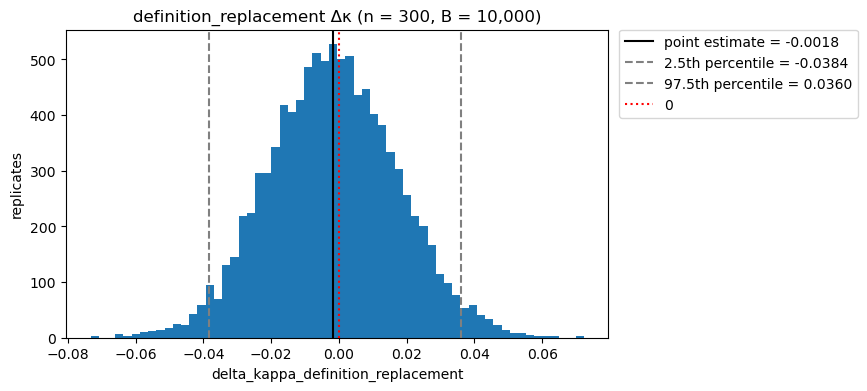

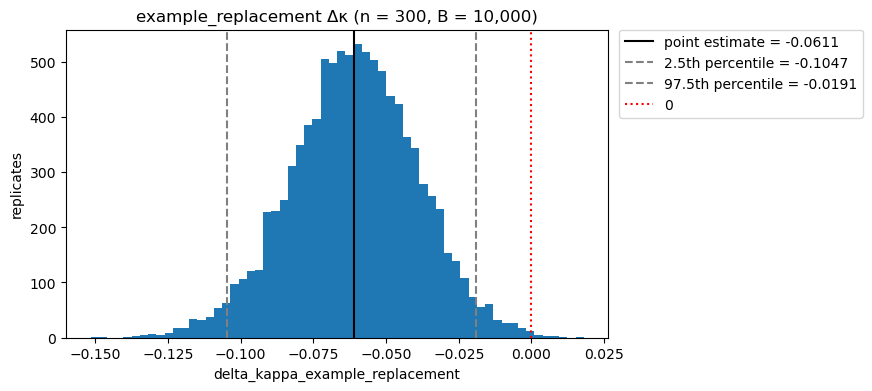

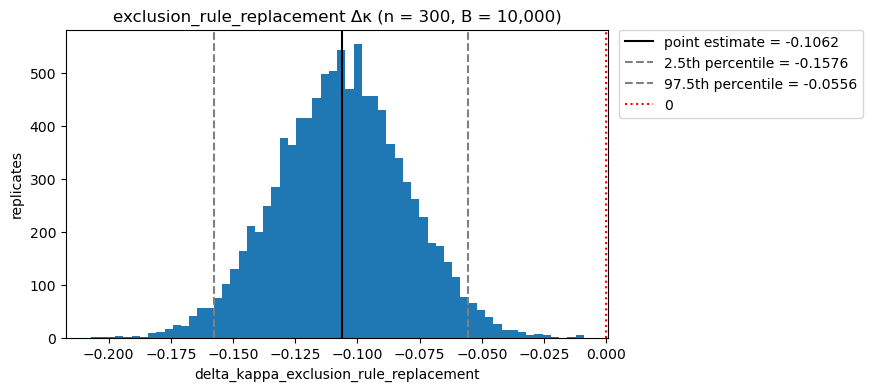

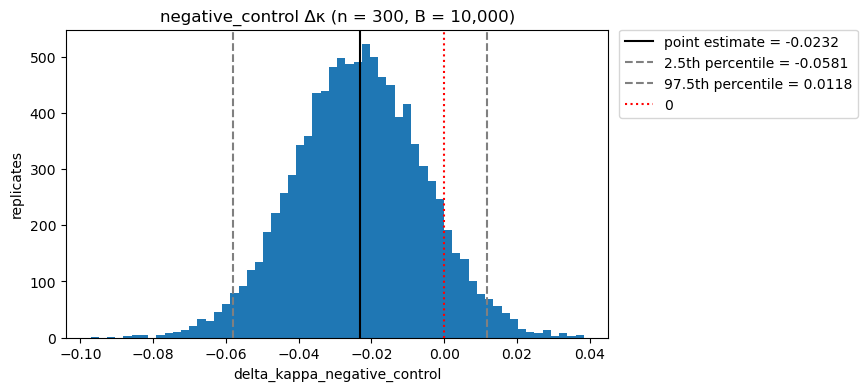

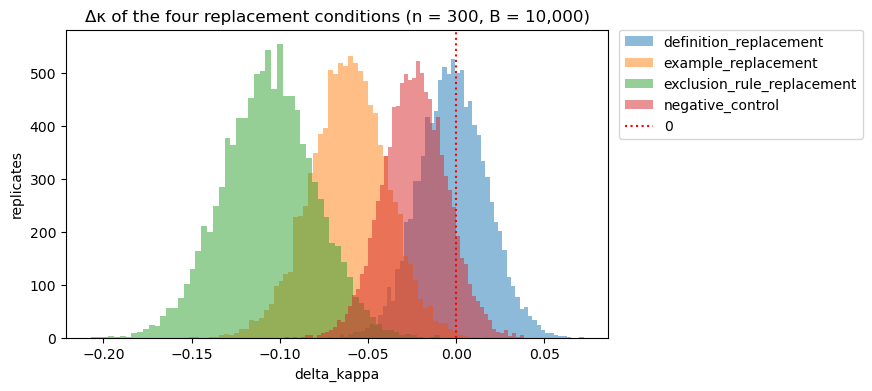

Condition                        corr  kappa width  delta width    ratio
baseline                                    0.1580                      
definition_replacement         0.8870       0.1572       0.0745   0.4713
example_replacement            0.8546       0.1581       0.0857   0.5421
exclusion_rule_replacement     0.7876       0.1522       0.1020   0.6456
negative_control               0.9010       0.1545       0.0700   0.4428

corr = correlation between baseline kappa and condition kappa across replicates
width = 97.5th minus 2.5th percentile; ratio = delta width / baseline kappa width


In [4]:
# 5.2. Delta kappa by condition

for c in REPLACEMENTS:
    fig, ax = plt.subplots(figsize=(7, 4))
    histogram(ax, replicates[f"delta_kappa_{c}"].to_numpy(), delta_point[c],
              f"{c} Δκ (n = {N}, B = {B:,})", f"delta_kappa_{c}", zero_line=True)
    plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for c in REPLACEMENTS:
    ax.hist(replicates[f"delta_kappa_{c}"].to_numpy(), bins=BINS, alpha=0.5, label=c)
ax.axvline(0, color="red", linestyle=":", label="0")
ax.set_title(f"Δκ of the four replacement conditions (n = {N}, B = {B:,})")
ax.set_xlabel("delta_kappa")
ax.set_ylabel("replicates")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0.0)
plt.show()

# Correlation between baseline kappa and condition kappa across replicates
kb = replicates["kappa_baseline"].to_numpy()
base_lo, base_hi = np.percentile(kb, [2.5, 97.5], method="linear")
base_width = base_hi - base_lo

print(f"{'Condition':<28} {'corr':>8} {'kappa width':>12} {'delta width':>12} {'ratio':>8}")
print(f"{'baseline':<28} {'':>8} {base_width:>12.4f} {'':>12} {'':>8}")
for c in REPLACEMENTS:
    kc = kb + replicates[f"delta_kappa_{c}"].to_numpy()          # restored condition kappa replicates
    lo, hi = np.percentile(kc, [2.5, 97.5], method="linear")
    assert round(lo, 4) == RECORD_KAPPA[c][1] and round(hi, 4) == RECORD_KAPPA[c][2], c
    d_lo, d_hi = np.percentile(replicates[f"delta_kappa_{c}"].to_numpy(), [2.5, 97.5], method="linear")
    corr = np.corrcoef(kb, kc)[0, 1]
    print(f"{c:<28} {corr:>8.4f} {hi - lo:>12.4f} {d_hi - d_lo:>12.4f} {(d_hi - d_lo) / base_width:>8.4f}")
print()
print("corr = correlation between baseline kappa and condition kappa across replicates")
print("width = 97.5th minus 2.5th percentile; ratio = delta width / baseline kappa width")

### 5.3. Percentile Intervals

`numpy.percentile(values, q, method="linear")` sorts the N values and interpolates between two neighbours.

For a proportion $p$ (0.025 or 0.975) the position in the sorted array (0-based) is

$$
\text{pos} = (N - 1) \times p
$$

With $N = 10{,}000$ and $p = 0.025$, $\text{pos} = 9999 \times 0.025 = 249.975$. Let $i = \lfloor \text{pos} \rfloor$ and $f = \text{pos} - i$. The percentile is the linear interpolation between the $i$-th and $(i+1)$-th sorted values:

$$
\text{percentile} = x_{(i)} + f \times \left(x_{(i+1)} - x_{(i)}\right)
$$

So the 2.5th percentile lies between the 249th and 250th sorted values (0-based), 97.5% of the way from the first to the second. For $p = 0.975$, $\text{pos} = 9749.025$, between the 9749th and 9750th sorted values.

The code reproduces this by hand for every column and checks the result against `numpy.percentile`. The comparison allows a tolerance of $10^{-12}$ because NumPy evaluates the interpolation in a slightly different floating-point order.

In [5]:
# 5.3. Percentile intervals by hand

def manual_percentile(values, p):
    x = np.sort(np.asarray(values, dtype=float))
    n = len(x)
    pos = (n - 1) * p
    i = int(np.floor(pos))
    f = pos - i
    return x[i] + f * (x[i + 1] - x[i]), pos, i, f

assert np.isclose(manual_percentile(np.arange(B), 0.025)[1], 249.975)   # (N - 1) * p = 9999 * 0.025, up to floating-point rounding

print(f"{'Statistic':<40} {'p':>6} {'pos':>10} {'i':>5} {'f':>6} {'by hand':>10} {'numpy':>10}")
for col, point, _ in STATS:
    values = replicates[col].to_numpy()
    for p in (0.025, 0.975):
        by_hand, pos, i, f = manual_percentile(values, p)
        by_numpy = float(np.percentile(values, 100 * p, method="linear"))
        assert np.isclose(by_hand, by_numpy, rtol=0, atol=1e-12), (col, p, by_hand, by_numpy)
        print(f"{col:<40} {p:>6.3f} {pos:>10.3f} {i:>5} {f:>6.3f} {by_hand:>10.4f} {by_numpy:>10.4f}")
print()
print("The hand calculation matches numpy.percentile for all five columns at both percentiles.")

Statistic                                     p        pos     i      f    by hand      numpy
kappa_baseline                            0.025    249.975   249  0.975     0.5266     0.5266
kappa_baseline                            0.975   9749.025  9749  0.025     0.6846     0.6846
delta_kappa_definition_replacement        0.025    249.975   249  0.975    -0.0384    -0.0384
delta_kappa_definition_replacement        0.975   9749.025  9749  0.025     0.0360     0.0360
delta_kappa_example_replacement           0.025    249.975   249  0.975    -0.1047    -0.1047
delta_kappa_example_replacement           0.975   9749.025  9749  0.025    -0.0191    -0.0191
delta_kappa_exclusion_rule_replacement    0.025    249.975   249  0.975    -0.1576    -0.1576
delta_kappa_exclusion_rule_replacement    0.975   9749.025  9749  0.025    -0.0556    -0.0556
delta_kappa_negative_control              0.025    249.975   249  0.975    -0.0581    -0.0581
delta_kappa_negative_control              0.975   9749.025  

## 6. Observations

작성 전: 그림과 수치를 보고 Jiwon이 직접 적는다

### Center

### Spread

### Shape

### Interval position

### What this experiment does not answer